In [1]:
# ============================================================================
# RUN THIS FIRST, ON A FRESH KERNEL, BEFORE ANY OTHER CELL.
# ============================================================================
# Two unrelated environment problems, both of which produce misleading errors.
#
# 1. torchmetrics imports a speech-quality metric (dnsmos) whenever librosa AND
#    onnxruntime are both installed. This machine's onnxruntime 1.21.0 has a
#    broken DLL, so that import raises and takes midi.datasets.qm9_dataset down
#    with it. Nothing in MiDi uses onnxruntime or librosa, so a stub is enough.
#    The __spec__ line is required: lightning_utilities checks availability with
#    importlib.util.find_spec, which rejects a module whose spec is None.
#
# 2. torch_geometric decides ONCE, at import time, whether pytorch_lightning is
#    importable, and caches the answer in its module globals. If it was first
#    imported while torchmetrics was broken, it cached "missing", and
#    QM9DataModule then fails with
#        ModuleNotFoundError: No module named 'pytorch_lightning'
#    That message is wrong. pytorch_lightning 2.5.5 IS installed. There is
#    nothing to pip install. The only cure is a kernel restart with this cell
#    run before any midi import.
import sys, types, importlib.machinery

if "onnxruntime" not in sys.modules:
    _stub = types.ModuleType("onnxruntime")
    _stub.__spec__ = importlib.machinery.ModuleSpec("onnxruntime", None)
    _stub.__version__ = "0.0.0"
    _stub.InferenceSession = object
    sys.modules["onnxruntime"] = _stub

_dm = "torch_geometric.data.lightning.datamodule"
if _dm in sys.modules and getattr(sys.modules[_dm], "no_pytorch_lightning", False):
    raise RuntimeError(
        "STALE KERNEL. torch_geometric cached 'pytorch_lightning missing' from an "
        "earlier failed import. Restart the kernel (Kernel > Restart) and run this "
        "cell first. pytorch_lightning IS installed; do not pip install it.")

print("onnxruntime stubbed. Safe to import midi.")

onnxruntime stubbed. Safe to import midi.


In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt


In [3]:
PATH_TO_ACTIVATIONS_POOLED = "../activations_test_full"
PATH_TO_ACTIVATIONS_RAW = "../activations_raw"

In [4]:
labels_pooled = np.load(f"{PATH_TO_ACTIVATIONS_POOLED}/labels.npz")
labels_raw = np.load(f"{PATH_TO_ACTIVATIONS_RAW}/labels.npz")

In [5]:
labels_raw['polarisability']

array([ 6.31, 42.32, 29.47, ..., 62.77, 71.28, 62.57])

In [6]:
np.quantile(labels_raw['polarisability'], 0.9)

76.411

In [7]:
activation_files_raw = [ i for i in os.listdir(PATH_TO_ACTIVATIONS_RAW) if i.startswith("node_")] 
activation_files_raw

['node_L09.npy', 'node_L10.npy', 'node_L11.npy', 'node_mask.npy']

In [8]:
layer_zero_activations_raw = np.load(f"{PATH_TO_ACTIVATIONS_RAW}/{activation_files_raw[0]}") 

In [9]:
layer_zero_activations_raw.shape

(10, 2000, 29, 256)

In [10]:
print(layer_zero_activations_raw[9].shape)

activations_raw_timestep_zero_df = layer_zero_activations_raw[9]
# activations_timestep_zero_df['polarisability'] = labels_raw['polarisability']
# activations_timestep_zero_df

(2000, 29, 256)


In [11]:
activations_raw_timestep_zero_df.shape

(2000, 29, 256)

In [12]:
labels_raw['polarisability']

array([ 6.31, 42.32, 29.47, ..., 62.77, 71.28, 62.57])

In [13]:
activations_raw_timestep_zero_df[0].shape

(29, 256)

In [14]:
pd.DataFrame(activations_raw_timestep_zero_df[0])

,0,1,2,3,4,5,6,7,8,9,...,246,247,248,249,250,251,252,253,254,255
0,0.167567,-0.091909,0.041163,-0.251821,2.826386,0.418426,1.921321,-1.362821,0.309051,0.325215,...,-1.178846,-0.298289,-0.958179,1.604412,0.073358,0.020938,0.946721,-0.846959,-1.337370,-0.679415
1,0.207146,-0.120172,1.119331,-0.727583,1.186710,-0.015799,0.504626,-1.345412,0.589783,0.340603,...,-0.851731,-0.344930,-1.127754,1.303968,0.689446,0.367093,0.403436,-1.644376,-0.665151,0.290423
2,0.138851,-0.073013,1.098018,-0.543029,0.872910,0.208739,0.090830,-1.390489,0.295469,0.386232,...,-0.815479,-0.387788,-1.253798,1.452928,0.630239,0.414247,0.874963,-1.726947,-0.791331,0.330638
3,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000
4,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000
5,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000
6,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000
7,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000
8,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000
9,0.000000,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,...,-0.000000,-0.000000,-0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000,-0.000000,-0.000000


In [15]:
upper_decile_polarisability = np.quantile(labels_raw['polarisability'], 0.9)
lower_decile_polarisability = np.quantile(labels_raw['polarisability'], 0.1)

print(upper_decile_polarisability)
print(lower_decile_polarisability)


76.411
56.47


In [16]:
lower_decile_polarisability_labels = labels_raw['polarisability'][np.where(labels_raw['polarisability'] < lower_decile_polarisability )]
upper_decile_polarisability_labels = labels_raw['polarisability'][np.where(labels_raw['polarisability'] > upper_decile_polarisability )]


In [17]:
max(lower_decile_polarisability_labels)

56.45

In [18]:
min(upper_decile_polarisability_labels)

76.42

In [19]:
layer_11_activations_raw = np.load(f"{PATH_TO_ACTIVATIONS_RAW}/node_L11.npy") 

In [20]:
layer_11_activations_raw.shape

(10, 2000, 29, 256)

In [21]:
lower_decile_indices = np.ravel(np.where(labels_raw['polarisability'] < lower_decile_polarisability ))
upper_decile_indices = np.ravel(np.where(labels_raw['polarisability'] > upper_decile_polarisability ))
lower_decile_activations_layer_11 = np.take(layer_11_activations_raw, lower_decile_indices, axis=1)
upper_decile_activations_layer_11 = np.take(layer_11_activations_raw, upper_decile_indices, axis=1)
print(lower_decile_activations_layer_11.shape)
print(upper_decile_activations_layer_11.shape)

(10, 199, 29, 256)
(10, 200, 29, 256)


In [22]:
labels_raw['polarisability']

array([ 6.31, 42.32, 29.47, ..., 62.77, 71.28, 62.57])

In [23]:
lower_decile_polarisability

56.47

In [24]:
graph_L11 = np.load(f"{PATH_TO_ACTIVATIONS_RAW}/graph_L11.npy") 
print(graph_L11.shape)
n_atoms = labels_raw["n_atoms"]    # (N,) including hydrogens
n_heavy = labels_raw["n_heavy"]    # (N,) heavy atoms only
print(n_atoms)
print(n_heavy)

(10, 2000, 128)
[ 3 10  8 ... 14 17 15]
[1 4 4 ... 8 8 8]


In [25]:
lower_decile_n_heavy_labels = labels_raw['n_heavy'][np.where(labels_raw['polarisability'] < lower_decile_polarisability )]
upper_decile_n_heavy_labels = labels_raw['n_heavy'][np.where(labels_raw['polarisability'] > upper_decile_polarisability )]


In [26]:
upper_decile_n_heavy_labels

array([7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8], dtype=int64)

In [27]:
lower_decile_n_heavy_labels

array([1, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8], dtype=int64)

Steps, in order (to determine decodability):

- Mask first. Drop padded atom slots using node_mask before anything else.
- Fix the vector. Pool per molecule (mean/min/max/var) or flatten per atom. Decide which and keep it fixed.
- Split by molecule, not by decile. Same 10,444 / 2,611 split you used, disjoint molecules.
- Standardise on train only. Fit mean and scale on train, apply to test.
- Regress out composition. Fit atom counts → polarisability on train, keep the residual. Skip this and you are decoding molecular formula.
- Fit the decoder. Ridge on the continuous value, or multinomial logistic on the decile label.
- Score on test. R² for regression; accuracy plus the confusion matrix for deciles.
- Permute labels 200×. Refit, take the 95th percentile as the floor.
- Compare to floor, not to zero.
- Repeat per layer and timestep. Report the best cell and where it sits.

In [28]:
node_mask_11 = np.load(f"{PATH_TO_ACTIVATIONS_RAW}/node_mask.npy") 

In [29]:
node_mask_11_upper_decile = node_mask_11[np.where(labels_raw['polarisability'] > upper_decile_polarisability )]
node_mask_11_lower_decile = node_mask_11[np.where(labels_raw['polarisability'] < lower_decile_polarisability )]

print(node_mask_11_upper_decile.shape)
print(node_mask_11_lower_decile.shape)

(200, 29)
(199, 29)


In [30]:

def masked_mean(act, mask):
    """Mean over REAL atoms only.  act (T, M, 29, C), mask (M, 29) -> (T, M, C).

    Padding rows are not zero: they hold whatever the layer computed for an
    unused slot. And the divisor is n_atoms, never 29, or the result is scaled
    by how empty the row is, which is itself almost a size readout.
    """
    m4 = mask[None, :, :, None]        # (1, M, 29, 1), broadcasts over T and C
    n3 = mask.sum(1)[None, :, None]    # (1, M, 1)
    return (act * m4).sum(2) / n3      # axis 2 is the ATOM axis

mean_upper_decile = masked_mean(upper_decile_activations_layer_11, node_mask_11_upper_decile)
mean_lower_decile = masked_mean(lower_decile_activations_layer_11, node_mask_11_lower_decile)

print(mean_upper_decile.shape)   # (10, 200, 256)
print(mean_lower_decile.shape)   # (10, 199, 256)

(10, 200, 256)
(10, 199, 256)


In [31]:
# GATE. The masked mean must reproduce the pooled store's X_mean block.
# If this fails, nothing downstream means anything, so run it before going on.

act_all  = np.asarray(np.load(f"{PATH_TO_ACTIVATIONS_RAW}/node_L11.npy", mmap_mode="r"))
mask_all = np.load(f"{PATH_TO_ACTIVATIONS_RAW}/node_mask.npy")
N = mask_all.shape[0]

mine = masked_mean(act_all, mask_all)                                              # (10, N, 256)
ref  = np.asarray(np.load(f"{PATH_TO_ACTIVATIONS_POOLED}/pooled_L11.npy",
                          mmap_mode="r")[:, :N, 128:384])                          # X_mean slice

print("n_atoms agrees  :", bool((mask_all.sum(1) == labels_raw["n_atoms"]).all()))
print("max abs diff    : %.3e" % np.abs(mine - ref).max())
print("matches pooled  :", np.allclose(mine, ref, atol=1e-3, rtol=1e-3))

# atol=1e-3, not 1e-4: the pooled store was summed by torch in a different order.
# 99.97% of entries agree to 1e-4; the worst is 1.2e-3 on a value of 0.47.

n_atoms agrees  : True
max abs diff    : 1.227e-03
matches pooled  : True


## Before fitting anything: these deciles are a size ranking

The top and bottom polarisability deciles are almost perfectly separated by heavy-atom
count alone. Any decoder trained on this split inherits that, so a high score is not
evidence that the activations carry polarisability.

Run the next cell and read the number before interpreting any result.

In [32]:
# How much of the decile split is just molecule size?

nh = labels_raw["n_heavy"]
U  = labels_raw["polarisability"] > upper_decile_polarisability
L  = labels_raw["polarisability"] < lower_decile_polarisability

print("n_heavy, upper decile:", np.bincount(nh[U], minlength=10)[:10])
print("n_heavy, lower decile:", np.bincount(nh[L], minlength=10)[:10])

best = max(((t, ((nh[U] >= t).sum() + (nh[L] < t).sum()) / (U.sum() + L.sum()))
            for t in range(12)), key=lambda p: p[1])
print(f"\nbest single threshold on n_heavy alone: n_heavy >= {best[0]}  ->  {best[1]*100:.1f}%")
print("chance = 50.0%")
print("\nSo a decoder has to beat this, not 50%, before it has shown anything.")

n_heavy, upper decile: [  0   0   0   0   0   0   0   3 197   0]
n_heavy, lower decile: [  0   1   0   0   3  13  58 104  20   0]

best single threshold on n_heavy alone: n_heavy >= 8  ->  94.2%
chance = 50.0%

So a decoder has to beat this, not 50%, before it has shown anything.


## The decodability test, with the size control

Two-group accuracy on extreme deciles throws away 80% of the molecules and inherits the
size confound above. Regression on the full set with composition regressed out is the
same question asked properly, and `midi/probe.py` already implements every piece:

- `composition_matrix` builds `[1, n_H, n_C, n_N, n_O, n_F]`, which spans `n_atoms` and `n_heavy`
- `residualize` fits that on **train only** and subtracts it, so the test labels never define the target
- `make_split` is the same molecule-level split the main probe grid used
- `CellSolver` + `fit_cell` choose lambda by exact leave-one-out, then score once on test

Three numbers come out. The third is the one to report.

In [33]:
labels_raw['n_C']

array([0, 4, 2, ..., 5, 6, 5], dtype=int64)

In [34]:
COMPOSITION_ELEMENTS = ("H", "C", "N", "O", "F")

n = len(labels_raw["n_atoms"])
cols = [np.ones(n)] + [labels_raw[f"n_{e}"].astype(np.float64) for e in COMPOSITION_ELEMENTS]
pd.DataFrame(cols).T

,0,1,2,3,4,5
0,1.0,2.0,0.0,0.0,1.0,0.0
1,1.0,6.0,4.0,0.0,0.0,0.0
2,1.0,4.0,2.0,0.0,2.0,0.0
3,1.0,4.0,2.0,0.0,2.0,0.0
4,1.0,4.0,4.0,0.0,1.0,0.0
...,...,...,...,...,...,...
1995,1.0,9.0,5.0,1.0,2.0,0.0
1996,1.0,7.0,6.0,1.0,1.0,0.0
1997,1.0,6.0,5.0,2.0,1.0,0.0
1998,1.0,9.0,6.0,1.0,1.0,0.0


In [35]:
import sys
sys.path.insert(0, "..")
from midi import probe

TI = 9   # index into ts = [500, 450, ..., 50]; index 9 is t=50, where every probe peaked

A = masked_mean(act_all, mask_all)[TI].astype(np.float64)      # (N, 256) masked mean
y = labels_raw["polarisability"].astype(np.float64)
C = probe.composition_matrix(labels_raw)                       # [1, n_H, n_C, n_N, n_O, n_F]

train, test = probe.make_split(len(y))
Ztr, Zte, d_used, d_drop = probe.standardize(A[train], A[test])
solver = probe.CellSolver(Ztr)

# 1. raw: activations -> polarisability
raw = probe.fit_cell(solver, Zte, y[train], y[test])

# 2. size only: composition with NO activations at all
b, *_ = np.linalg.lstsq(C[train], y[train], rcond=None)
r2_size = probe.r2(y[test], (C @ b)[test])

# 3. residual: activations -> what composition could not explain
y_res, _ = probe.residualize(y, C, train)
res = probe.fit_cell(solver, Zte, y_res[train], y_res[test])

print(f"raw R2        {raw['r2']:.4f}")
print(f"size-only R2  {r2_size:.4f}   <- composition alone, no activations")
print(f"residual R2   {res['r2']:.4f}   <- report this one")
print()
print(f"n_train {len(train)}  n_test {len(test)}  d_used {d_used}  dropped {d_drop}")
print(f"molecules per dimension {raw['n_per_dim']:.1f}")
print(f"lambda {res['lam']:.3g}   at grid edge: {res['lam_at_grid_edge']}")
if res["lam_at_grid_edge"]:
    print("  -> lambda hit the edge of LAM_GRID. Treat the R2 as a lower bound,")
    print("     or widen probe.LAM_GRID and refit.")

raw R2        0.9799
size-only R2  0.8987   <- composition alone, no activations
residual R2   0.8521   <- report this one

n_train 1600  n_test 400  d_used 256  dropped 0
molecules per dimension 6.2
lambda 1e-06   at grid edge: True
  -> lambda hit the edge of LAM_GRID. Treat the R2 as a lower bound,
     or widen probe.LAM_GRID and refit.


In [36]:
# Permutation floor: 200 shuffles of the residual target, same split, same solver.
# floor_stats() needs scipy for its z-score, so the floor is computed directly here.

Y = probe.permute_targets(y_res, 200, seed=20261116)
r2_null, _ = probe.fit_many(solver, Zte, Y[train], Y[test])

p95    = float(np.percentile(r2_null, 95))
exceed = int((r2_null >= res["r2"]).sum())

print(f"observed residual R2  {res['r2']:.4f}")
print(f"null mean             {r2_null.mean():.4f}")
print(f"null 95th percentile  {p95:.4f}")
print(f"permutations >= obs   {exceed} / 200      p = {(1 + exceed) / 201:.4g}")
print()
print("ABOVE FLOOR" if res["r2"] > p95 else "AT OR BELOW FLOOR")

observed residual R2  0.8521
null mean             -0.0036
null 95th percentile  0.0002
permutations >= obs   0 / 200      p = 0.004975

ABOVE FLOOR


In [37]:
Y.shape

(2000, 200)

In [38]:
def diff_of_means(A, y, q=0.5, min_per_side=10):
    lo_thr, hi_thr = np.quantile(y, q), np.quantile(y, 1.0 - q)
    L, H = y <= lo_thr, y >= hi_thr
    return A[H].mean(axis=0) - A[L].mean(axis=0), int(H.sum()), int(L.sum())

In [39]:
A.shape

(2000, 256)

In [40]:
delta_mu, h_sum, l_sum = diff_of_means(A, y)

In [41]:
delta_mu.shape

(256,)

In [42]:
import math
magnitude_d = math.sqrt(sum([i**2 for i in delta_mu]))

In [43]:
v = delta_mu / magnitude_d

In [44]:
v.shape

(256,)

In [45]:
g_, yc_, ym_ = solver.prepare(y_res[train])
lam_w, sse_w, at_edge_w = solver.choose_lam(g_, yc_)
w = solver.coef_from_g(g_, lam_w)

print("w shape      ", w.shape)
print("lambda       ", f"{lam_w:.3g}")
print("matches fit  ", bool(np.isclose(lam_w, res["lam"])))

w shape       (256,)
lambda        1e-06
matches fit   True


In [46]:
w.shape

(256,)

In [47]:
d, n_hi, n_lo = diff_of_means(Ztr, y[train])

print(f"d from {n_hi} high vs {n_lo} low TRAIN molecules, shape {d.shape}")
print("cos(your delta_mu, this d) =", round(float(
    (delta_mu/np.linalg.norm(delta_mu)) @ (d/np.linalg.norm(d))), 4))

d from 800 high vs 800 low TRAIN molecules, shape (256,)
cos(your delta_mu, this d) = 0.9639


In [48]:
unit = lambda x: x / np.linalg.norm(x)
cos  = lambda a, b: float(unit(a) @ unit(b))

print(f"cos(d, w)        {cos(d, w):+.4f}")
print(f"chance 1/sqrt(p) {1/np.sqrt(d_used):+.4f}")

cos(d, w)        +0.0079
chance 1/sqrt(p) +0.0625


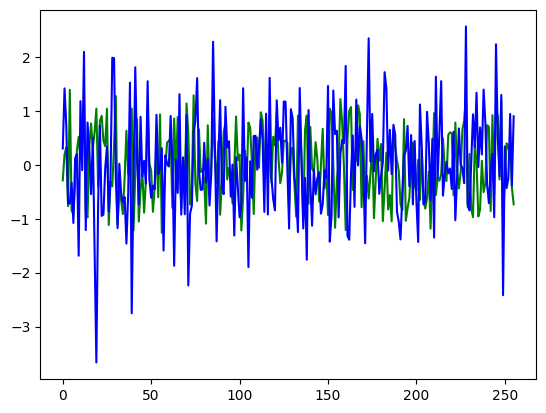

In [49]:
plt.plot([ i for i in range(len(d))], d, color='green')
plt.plot([ i for i in range(len(d))], w, color='blue')

In [50]:
unit = lambda x: x / np.linalg.norm(x)
cos  = lambda a, b: float(unit(a) @ unit(b))

print(f"cos(d, w)        {cos(d, w):+.4f}")
print(f"chance 1/sqrt(p) {1/np.sqrt(d_used):+.4f}")

cos(d, w)        +0.0079
chance 1/sqrt(p) +0.0625


In [51]:
S = (Ztr.T @ Ztr) / len(train)
evals, evecs = np.linalg.eigh(S)
order = np.argsort(evals)[::-1]
evals, V = evals[order], evecs[:, order]

print(f"top 10 of {d_used} directions carry {evals[:10].sum()/evals.sum()*100:.1f}% of variance")
print(f"top 50 carry {evals[:50].sum()/evals.sum()*100:.1f}%")
for nm, vec in (("d", d), ("w", w)):
    p = (V.T @ unit(vec))**2
    print(f"  {nm}: {p[:10].sum()*100:5.1f}% in top-10, {p[:50].sum()*100:5.1f}% in top-50")

top 10 of 256 directions carry 83.2% of variance
top 50 carry 98.3%
  d:  99.4% in top-10, 100.0% in top-50
  w:   0.1% in top-10,   1.1% in top-50


In [52]:
for lam_white in (1e-3, 1e-2, 1e-1):
    d_white = np.linalg.solve(S + lam_white*np.eye(d_used), d)
    print(f"cos(whitened d, w)  lam={lam_white:<6} {cos(d_white, w):+.4f}")

cos(whitened d, w)  lam=0.001  +0.2607
cos(whitened d, w)  lam=0.01   +0.1672
cos(whitened d, w)  lam=0.1    +0.1028


In [53]:
print(S.shape)
print(lam_white)
print(d_used)
print(d.shape)

(256, 256)
0.1
256
(256,)


In [54]:
spread = lambda vec: float((Ztr @ unit(vec)).std())

for nm, vec in (("d", d), ("w", w)):
    print(f"  {nm}: data spread {spread(vec):7.3f}")
print(f"ratio {spread(d)/spread(w):.1f}x")
for c in (10, 20, 40):
    print(f"  c={c:3d}: {c/spread(d):6.2f} sd along d   {c/spread(w):9.2f} sd along w")

  d: data spread   7.796
  w: data spread   0.158
ratio 49.3x
  c= 10:   1.28 sd along d       63.24 sd along w
  c= 20:   2.57 sd along d      126.49 sd along w
  c= 40:   5.13 sd along d      252.98 sd along w


In [55]:
import sys, types, importlib.machinery

# torchmetrics imports a speech-quality metric when librosa AND onnxruntime are
# both installed, and this onnxruntime build has a broken DLL. Nothing in MiDi
# uses either. A stub satisfies the import so torchmetrics loads.
if "onnxruntime" not in sys.modules:
    _stub = types.ModuleType("onnxruntime")
    _stub.__spec__ = importlib.machinery.ModuleSpec("onnxruntime", None)
    _stub.__version__ = "0.0.0"
    _stub.InferenceSession = object
    sys.modules["onnxruntime"] = _stub

In [56]:
# Environment check. Fast, no model load.
# If the assert fires: Kernel > Restart, then run cell 0 before anything else.
import pytorch_lightning as pl
from torch_geometric.data.lightning.datamodule import no_pytorch_lightning

print("pytorch_lightning       ", pl.__version__)
print("torch_geometric sees it ", not no_pytorch_lightning)
assert not no_pytorch_lightning, "RESTART THE KERNEL, then run cell 0 first."

pytorch_lightning        2.5.5
torch_geometric sees it  True


In [57]:
import os, sys, numpy as np, torch
sys.path.insert(0, "..")

import midi._compat                      # torch.load default; must precede any load
from hydra import initialize_config_dir, compose
import midi.datasets.qm9_dataset as qm9ds
from midi.diffusion_model import FullDenoisingDiffusion

REPO = os.path.abspath("..")
CKPT = os.path.join(REPO, "midi", "checkpoints", "checkpoint_qm9_h_adaptive.ckpt")

# QM9DataModule calls hydra's get_original_cwd(), which only exists inside a
# @hydra.main run. The scripts run from midi/, and it takes parents[0] of that,
# so point it at midi/ and the data root resolves to <repo>/data/qm9/qm9_pyg/.
qm9ds.get_original_cwd = lambda: os.path.join(REPO, "midi")

with initialize_config_dir(config_dir=os.path.join(REPO, "configs"), version_base="1.3"):
    cfg = compose(config_name="config", overrides=[
        "dataset=qm9", "dataset.remove_h=False",
        "+experiment=qm9_with_h_adaptive", "general.wandb=disabled",
        "general.gpus=1", f"general.test_only={CKPT}",
    ])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
datamodule = qm9ds.QM9DataModule(cfg)
dinfos     = qm9ds.QM9infos(datamodule=datamodule, cfg=cfg)
model = FullDenoisingDiffusion.load_from_checkpoint(
    CKPT, dataset_infos=dinfos, train_smiles=[]).to(device).eval()

assert not model.training, "eval mode is mandatory: dropout is 0.1"
print("T =", model.T, "| layers =", model.model.n_layers, "| device =", device)

NUM NODES IN STATISTICS Counter({19: 13531, 18: 12970, 17: 12691, 16: 10332, 21: 9889, 20: 9194, 15: 7700, 14: 5102, 23: 4765, 22: 3324, 13: 2960, 12: 1632, 25: 1397, 11: 799, 24: 538, 10: 358, 27: 270, 9: 132, 8: 50, 26: 42, 29: 26, 7: 16, 6: 9, 5: 3, 4: 3, 3: 1})
NUM NODES IN STATISTICS Counter({19: 2808, 18: 2685, 17: 2554, 16: 2129, 21: 1982, 20: 1917, 15: 1528, 14: 1013, 23: 974, 22: 677, 13: 653, 12: 359, 25: 313, 11: 160, 24: 112, 10: 75, 27: 46, 9: 25, 26: 12, 8: 9, 6: 3, 29: 3, 7: 2, 5: 2, 4: 1})
NUM NODES IN STATISTICS Counter({19: 1807, 18: 1787, 17: 1724, 16: 1363, 21: 1295, 20: 1292, 15: 988, 14: 643, 23: 623, 22: 427, 13: 414, 25: 213, 12: 198, 11: 94, 24: 62, 10: 50, 27: 40, 9: 15, 8: 6, 29: 6, 26: 5, 7: 2, 3: 1})


C:\Users\tsuma.thomas\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch_geometric\data\lightning\datamodule.py:43: The 'shuffle=True' option is ignored in 'QM9DataModule'. Remove it from the argument list to disable this warning
Lightning automatically upgraded your loaded checkpoint from v1.6.5 to v2.5.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint C:\Users\tsuma.thomas\Documents\MiDi-ActivationSteering\midi\checkpoints\checkpoint_qm9_h_adaptive.ckpt`


Marginal distribution of the classes: nodes: tensor([0.5121, 0.3528, 0.0562, 0.0776, 0.0013]) -- edges: tensor([0.8818, 0.1105, 0.0060, 0.0018, 0.0000]) -- charges: tensor([0.0038, 0.9856, 0.0106])
T = 500 | layers = 12 | device = cuda


In [58]:
from midi import direction, steer
from midi import rng as midi_rng

LAYER, BLOCK, CHANNEL = 10, "X_mean", "X"
WINDOW = (50, 100)          # the late window your sweep used
SEED   = 1234

res = direction.load(os.path.join(REPO, "results", "directions",
                                  f"dir_L{LAYER}_{BLOCK}_polarisability.npz"))
ts = np.asarray(res["timesteps"])

# d: one direction per captured timestep, composition-residualised
D_dom   = np.asarray(res["d_resid"])            # (10, 256)
nrm_dom = np.linalg.norm(D_dom, axis=1)
V_dom   = D_dom / nrm_dom[:, None]

# w: one direction, already mapped back to RAW activation space
w       = np.asarray(res["w_probe_raw"])        # (256,)
V_probe = np.repeat((w / np.linalg.norm(w))[None, :], len(ts), axis=0)
nrm_probe = np.full(len(ts), float(nrm_dom[list(ts).index(50)]))

print("timesteps      ", ts)
print("||d|| at t=50  ", nrm_dom[list(ts).index(50)])
print("||w||          ", np.linalg.norm(w))

timesteps       [500 450 400 350 300 250 200 150 100  50]
||d|| at t=50   0.996390255951384
||w||           53.0282488531806


In [59]:
# --- choose the coefficients ------------------------------------------------
# MATCHED INJECTED NORM. Both arms inject a vector of the same length, so both
# reach the same rho (the factor by which the activation norm grows). This is
# what run_pilot.py already does via nrm_probe = nrm_dom.
#
# An earlier version of this cell matched OFF-MANIFOLD DISTANCE instead, which
# sounds principled and is wrong here: the data spread along w is 0.0528 versus
# 0.7947 along d, so being 25 sd out along w is a tiny absolute displacement.
# It gave C_PROBE = 1.33, rho = 1.014, a 1.4% change in the activation, far too
# small to flip any discrete argmax. Every molecule came back bit-identical.
#
# The two criteria cannot both be met along w:
#     match off-manifold sd -> C_PROBE 1.33,  rho 1.014,  nothing moves
#     match injected norm   -> C_PROBE 20.0,  rho 2.757,  377 sd off-manifold
# That is a real structural fact about this direction, not a tuning problem.
i50   = list(ts).index(50)
A_blk = direction.load_block(os.path.join(REPO, "activations_test_full"),
                             LAYER, int(np.where(ts == 50)[0][0]), BLOCK)
unit   = lambda x: x / np.linalg.norm(x)
spread = lambda v: float((A_blk @ unit(v)).std())
a_norm = float(np.linalg.norm(A_blk, axis=1).mean())

s_d, s_w = spread(D_dom[i50]), spread(w)

C_DOM   = 20.0
C_PROBE = 20.0            # matched injected norm

for nm, c, s in (("dom", C_DOM, s_d), ("probe", C_PROBE, s_w)):
    L = c * nrm_dom[i50]
    print(f"{nm:6s} coeff {c:5.1f}  injected length {L:7.3f}  "
          f"predicted rho {np.sqrt(1 + (L/a_norm)**2):5.3f}  "
          f"{L/s:7.1f} sd off-manifold")
print(f"\n||a|| mean {a_norm:.3f}   data spread: d {s_d:.4f}, w {s_w:.4f}")
print("your sweep measured rho 2.71 at dom c=+20, so expect ~2.76 here")

dom    coeff  20.0  injected length  19.928  predicted rho 2.757     25.1 sd off-manifold
probe  coeff  20.0  injected length  19.928  predicted rho 2.757    377.1 sd off-manifold

||a|| mean 7.755   data spread: d 0.7947, w 0.0528
your sweep measured rho 2.71 at dom c=+20, so expect ~2.76 here


In [60]:
# --- one function that runs a single arm -----------------------------------
N_MAX = 29

def run_arm(V, N, coeff, ids):
    """Generate len(ids) molecules with the given direction and coefficient.

    Returns (mols, state). The state carries n_injected, rho and cos, which is
    what separates "the hook never fired" from "the hook fired and the
    perturbation was too small". Those are different failures and they look
    identical in the MolMR table.

    coeff = 0 attaches no hooks at all, which is the unsteered control.
    ids and SEED are shared across arms, so sample_n_nodes gives every arm the
    same molecule sizes and run_seed the same starting noise: molecule 7 here
    and molecule 7 in the control begin identically and differ only by the
    injection. That pairing is what makes 32 molecules informative.
    """
    state = None
    if coeff != 0.0:
        state = steer.SteerState(layer=LAYER, channel=CHANNEL, v=V, d_norm=N,
                                 coeff=coeff, window=WINDOW, T=model.T,
                                 device=device, v_timesteps=ts)
    handles = steer.attach(model, state) if state is not None else []
    try:
        n_nodes = midi_rng.sample_n_nodes(SEED, ids, model.node_dist.prob)
        with torch.no_grad():
            mols = model.sample_batch(
                n_nodes=n_nodes.tolist(), mol_ids=list(ids), run_seed=SEED,
                n_max_fixed=N_MAX, test=True, save_final=0, keep_chain=0,
                visualize=False, batch_id=0)
    finally:
        steer.detach(handles)      # must happen even on error, or later cells steer
    return mols, state

In [64]:
V_dom

array([[ 0.02464937, -0.00636988,  0.11392774, ...,  0.02780529,
         0.05082346, -0.06279735],
       [-0.03748161,  0.0176573 ,  0.0867888 , ...,  0.0437642 ,
         0.04816   , -0.07712126],
       [-0.02047821, -0.00613974,  0.10933448, ...,  0.04297189,
         0.04669009, -0.08408335],
       ...,
       [-0.11035213,  0.0817162 , -0.00954145, ..., -0.00787756,
         0.04923265, -0.05301107],
       [-0.11685751,  0.07889545, -0.00916456, ..., -0.02666346,
         0.04256215, -0.06773113],
       [-0.10785048,  0.07221064,  0.01066586, ..., -0.06435044,
         0.03731641, -0.08528097]])

In [61]:
# --- run five arms ----------------------------------------------------------
# Both signs matter. A direction that really encodes the property moves it UP at
# +c and DOWN at -c. If both signs push the same way, that is damage, not
# steering, and it answers the question without any diagnostics.
IDS = list(range(32))          # ~12 min total on the 4050

arms = {
    "control":  (V_dom,   nrm_dom,   0.0),
    "dom +":    (V_dom,   nrm_dom,   +C_DOM),
    "dom -":    (V_dom,   nrm_dom,   -C_DOM),
    "probe +":  (V_probe, nrm_probe, +C_PROBE),
    "probe -":  (V_probe, nrm_probe, -C_PROBE),
}

out, states = {}, {}
for name, (V, N, c) in arms.items():
    print(f"--- {name}  coeff={c:+.4f}", flush=True)
    out[name], states[name] = run_arm(V, N, c, IDS)
    s = states[name]
    if s is None:
        print("    no hooks (control)")
    else:
        rho, cos = s.per_molecule()
        print(f"    injected {s.n_injected} steps | rho {rho.mean():.3f} | cos {cos.mean():.3f}")
        if s.n_injected == 0:
            print("    WARNING: hook never fired. Check WINDOW against the sampling loop.")
        elif rho.mean() < 1.02:
            print("    WARNING: rho ~1, the perturbation is too small to change a "
                  "discrete output. Raise the coefficient.")

--- control  coeff=+0.0000
Sampling a batch with 32 graphs. Saving 0 visualization and 0 full chains.
    no hooks (control)
--- dom +  coeff=+20.0000
Sampling a batch with 32 graphs. Saving 0 visualization and 0 full chains.
    injected 51 steps | rho 2.735 | cos 0.931
--- dom -  coeff=-20.0000
Sampling a batch with 32 graphs. Saving 0 visualization and 0 full chains.
    injected 51 steps | rho 2.828 | cos -0.936
--- probe +  coeff=+20.0000
Sampling a batch with 32 graphs. Saving 0 visualization and 0 full chains.
    injected 51 steps | rho 2.699 | cos 0.929
--- probe -  coeff=-20.0000
Sampling a batch with 32 graphs. Saving 0 visualization and 0 full chains.
    injected 51 steps | rho 2.882 | cos -0.938


In [62]:
# --- measure and compare ----------------------------------------------------
from rdkit import Chem
from rdkit.Chem import Crippen

ATOM_DECODER = ("H", "C", "N", "O", "F")
BOND = [None, Chem.BondType.SINGLE, Chem.BondType.DOUBLE,
        Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

def _rdmol(m):
    rw = Chem.RWMol()
    for a, c in zip(m.atom_types.cpu().numpy(), m.charges.cpu().numpy()):
        at = Chem.Atom(ATOM_DECODER[int(a)])
        if int(c) != 0:
            at.SetFormalCharge(int(c))
        rw.AddAtom(at)
    E = np.triu(m.bond_types.cpu().numpy(), 1)
    for i, j in zip(*np.nonzero(E)):
        b = int(E[i, j])
        if 1 <= b <= 4:
            rw.AddBond(int(i), int(j), BOND[b])
    try:
        mol = rw.GetMol()
        Chem.SanitizeMol(mol)
        return mol
    except Exception:
        return None

def molmr(m):
    """Crippen molar refractivity: the stand-in for polarisability, the two are
    linked by the Lorentz-Lorenz relation. NaN if the graph will not sanitise."""
    mol = _rdmol(m)
    return np.nan if mol is None else float(Crippen.MolMR(mol))

def molmr_per_heavy(m):
    """MolMR divided by heavy-atom count.

    MolMR is EXTENSIVE: it rises whenever a molecule gains atoms, with no change
    in polarisability per atom. Your sweep was caught by exactly this at c=+40
    and +80, where raw MolMR rose while the per-heavy-atom figure FELL, because
    the molecules simply got bigger. At 32 molecules this is the only endpoint
    worth reading."""
    mol = _rdmol(m)
    if mol is None:
        return np.nan
    h = mol.GetNumHeavyAtoms()
    return np.nan if h == 0 else float(Crippen.MolMR(mol)) / h

mr   = {k: np.array([molmr(m)           for m in v]) for k, v in out.items()}
mrh  = {k: np.array([molmr_per_heavy(m) for m in v]) for k, v in out.items()}

def paired(x, base):
    ok = ~np.isnan(x) & ~np.isnan(base)
    return (np.nan, 0) if ok.sum() == 0 else (float((x[ok] - base[ok]).mean()), int(ok.sum()))

print(f"{'arm':<10}{'valid':>8}{'MolMR':>9}{'dMolMR':>9}{'MR/heavy':>10}"
      f"{'dMR/heavy':>11}{'n pair':>8}{'moves':>7}")
for name in arms:
    d_raw, n1 = paired(mr[name],  mr["control"])
    d_hv,  _  = paired(mrh[name], mrh["control"])
    arrow = "" if name == "control" else ("UP" if d_hv > 0 else "DOWN")
    print(f"{name:<10}{int((~np.isnan(mr[name])).sum()):>5}/{len(mr[name]):<2}"
          f"{np.nanmean(mr[name]):>9.3f}{d_raw:>9.3f}"
          f"{np.nanmean(mrh[name]):>10.3f}{d_hv:>11.4f}{n1:>8}{arrow:>7}")

print()
print("Read the dMR/heavy column, not dMolMR. Looking for '+' and '-' arms with")
print("OPPOSITE signs. Same sign on both = degradation, not steering.")
print("n pair is molecules valid in BOTH arms; it differs per arm, so the sets")
print("being compared are not identical. 32 molecules cannot give significance.")

arm          valid    MolMR   dMolMR  MR/heavy  dMR/heavy  n pair  moves
control      32/32   31.615    0.000     3.602     0.0000      32       
dom +        28/32   31.856    0.331     3.722     0.1046      28     UP
dom -        28/32   32.125    0.062     3.618    -0.0090      28   DOWN
probe +      32/32   31.615    0.000     3.602     0.0000      32   DOWN
probe -      32/32   31.615    0.000     3.602     0.0000      32   DOWN

Read the dMR/heavy column, not dMolMR. Looking for '+' and '-' arms with
OPPOSITE signs. Same sign on both = degradation, not steering.
n pair is molecules valid in BOTH arms; it differs per arm, so the sets
being compared are not identical. 32 molecules cannot give significance.


In [63]:
# --- coefficient ladder for the probe arm -----------------------------------
# Run this only if the matched-norm probe arm came back near 0 valid. At 377 sd
# off-manifold that is a real possibility, and it is itself a finding. This
# locates where the probe direction starts to bite instead of guessing.
# 16 molecules per rung, four rungs, roughly 10 minutes.

print(f"{'c':>6}{'rho':>7}{'valid':>9}{'MolMR':>9}{'MR/heavy':>10}")
for c in (2.0, 5.0, 10.0, 20.0):
    mols, s = run_arm(V_probe, nrm_probe, c, IDS[:16])
    x  = np.array([molmr(m) for m in mols])
    xh = np.array([molmr_per_heavy(m) for m in mols])
    rho, _ = s.per_molecule()
    print(f"{c:>6.1f}{rho.mean():>7.2f}{int((~np.isnan(x)).sum()):>6}/16"
          f"{np.nanmean(x):>9.3f}{np.nanmean(xh):>10.3f}")

     c    rho    valid    MolMR  MR/heavy
Sampling a batch with 16 graphs. Saving 0 visualization and 0 full chains.
   2.0   1.01    16/16   31.670     3.578
Sampling a batch with 16 graphs. Saving 0 visualization and 0 full chains.
   5.0   1.14    16/16   31.670     3.578
Sampling a batch with 16 graphs. Saving 0 visualization and 0 full chains.
  10.0   1.57    16/16   31.670     3.578
Sampling a batch with 16 graphs. Saving 0 visualization and 0 full chains.
  20.0   2.71    16/16   31.670     3.578


In [ ]:
# --- polarisability surrogate: fit once, cache, reuse -----------------------
# MolMR was a stand-in. This reads the property in its own unit.
#
# Polarisability in QM9 is a DFT observable (alpha, Bohr^3). It is not a graph
# property, so RDKit cannot compute it and a generated molecule has no label.
# The options are a QM calculation per molecule (GFN2-xTB, the gold standard and
# not installed here), or a model calibrated on QM9's own labels. This is the
# second. It fits graph descriptors -> alpha on the 13,055 labelled test
# molecules, so every arm difference below is quoted in Bohr^3 against a
# measured held-out accuracy instead of in MolMR units.
#
# Takes about a minute the first time (it builds ~13k RDKit mols), then loads
# from results/alpha_surrogate.npz. Pass refit=True to rebuild.
from midi import alpha_surrogate as alpha

SURROGATE = os.path.join(REPO, "results", "alpha_surrogate.npz")
amodel, fresh = alpha.fit_or_load(
    SURROGATE,
    dataset=datamodule.test_dataloader().dataset,
    labels_npz=os.path.join(REPO, "activations_test_full", "labels.npz"),
    atom_decoder=tuple(dinfos.atom_decoder),
    refit=False,
)
print("fitted now" if fresh else f"loaded {SURROGATE}")
print(f"  trained on {amodel['n_train']}, held out {amodel['n_holdout']}")
for tag, lab in (("full", "all 20 descriptors"), ("comp", "composition only")):
    m = amodel[tag]
    print(f"  {lab:<20} R2 {m['r2']:.4f}  MAE {m['mae']:.3f}  "
          f"RMSE {m['rmse']:.3f} Bohr^3")
print(f"  sd(alpha) {amodel['y_sd']:.2f}  mean(alpha) {amodel['y_mean']:.2f} "
      f"Bohr^3   h* {amodel['h_star']:.4f}")
print()
print("The composition-only row is the one to keep in mind: atom counts alone")
print("already explain R2 0.87 of polarisability. That is why the table reports")
print("d_beyond, the shift that composition does NOT account for.")


In [ ]:
# --- polarisability of the generated molecules, by arm ----------------------
# Reads `out`, the dict of arms from the generation cell above, so run this
# after it. Every arm shares the same molecule ids in the same order, which is
# what makes each difference a PAIRED one against the control.
#
# What to read, in order:
#   d_alpha    did polarisability move, in Bohr^3
#   t          is that move bigger than the pair-to-pair scatter
#   d_beyond   is any of it left once the arm's composition change is removed
#   + vs -     do the two signs move OPPOSITE ways; same sign is damage
readouts = {name: alpha.predict_molecules(amodel, mols,
                                          tuple(dinfos.atom_decoder))
            for name, mols in out.items()}

rows = alpha.arm_table(readouts, control="control", h_star=amodel["h_star"])
alpha.print_table(rows, amodel)

# The sign test, stated outright rather than left to the eye.
print()
for pos, neg in (("dom +", "dom -"), ("probe +", "probe -")):
    if pos in readouts and neg in readouts:
        a = next(r for r in rows if r["arm"] == pos)
        b = next(r for r in rows if r["arm"] == neg)
        for key, lab in (("d_alpha", "d_alpha "), ("d_beyond", "d_beyond")):
            x, y = a[key], b[key]
            if not (np.isfinite(x) and np.isfinite(y)):
                verdict = "not computable"
            elif abs(x) < 1e-9 and abs(y) < 1e-9:
                verdict = "both exactly zero: the injection changed nothing"
            elif x * y < 0:
                verdict = "OPPOSITE signs: consistent with steering"
            else:
                verdict = "SAME sign: damage, not steering"
        
            print(f"  {pos:<8} vs {neg:<8} {lab} {x:+8.3f} / {y:+8.3f}   {verdict}")
